# Option C: Graph Neural Network using Gene Co-expression Network

This notebook implements a Graph Neural Network model for binary cancer classification using selected gene expression features.

Each gene is represented as a node in a graph. Edges between genes are constructed based on Pearson correlation computed from the training data only. For each patient sample, gene expression values are used as node features. The GNN learns sample-level representations by propagating information among correlated genes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import matplotlib.pyplot as plt

In [ ]:
#Cố định seed và chọn GPU
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
BASE_DIR = Path("/content/drive/MyDrive/gene_project")

RESULT_DIR = BASE_DIR / "results_gnn"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

X_TRAIN_PATH = BASE_DIR / "X_train_rF_DEG_train_lung.csv"
X_TEST_PATH = BASE_DIR / "X_test_rF_DEG_train_lung.csv"
Y_TRAIN_PATH = BASE_DIR / "y_train_rF_DEG_train.csv"
Y_TEST_PATH = BASE_DIR / "y_test_rF_DEG_train.csv"

In [ ]:
#Load dữ liệu
X_train_full = pd.read_csv(X_TRAIN_PATH)
X_test = pd.read_csv(X_TEST_PATH)

y_train_full = pd.read_csv(Y_TRAIN_PATH)
y_test = pd.read_csv(Y_TEST_PATH)

print("Raw X_train:", X_train_full.shape)
print("Raw X_test:", X_test.shape)
print("Raw y_train:", y_train_full.shape)
print("Raw y_test:", y_test.shape)

Raw X_train: (730, 211)
Raw X_test: (183, 211)
Raw y_train: (730, 1)
Raw y_test: (183, 1)


Làm sạch dữ liệu

In [ ]:
def clean_feature_df(X_df):
    X_df = X_df.copy()
    X_df = X_df.loc[:, ~X_df.columns.str.contains("^Unnamed")]
    return X_df


def clean_label_df(y_df):
    y_df = y_df.copy()
    y_df = y_df.loc[:, ~y_df.columns.str.contains("^Unnamed")]

    # lấy cột cuối làm label
    y_series = y_df.iloc[:, -1]

    return y_series.astype(int)


X_train_full = clean_feature_df(X_train_full)
X_test = clean_feature_df(X_test)

y_train_full = clean_label_df(y_train_full)
y_test = clean_label_df(y_test)

print("Clean X_train:", X_train_full.shape)
print("Clean X_test:", X_test.shape)
print("Clean y_train:", y_train_full.shape)
print("Clean y_test:", y_test.shape)

print("\nTrain label distribution:")
print(y_train_full.value_counts())

print("\nTest label distribution:")
print(y_test.value_counts())

Clean X_train: (730, 211)
Clean X_test: (183, 211)
Clean y_train: (730,)
Clean y_test: (183,)

Train label distribution:
cancer_type
1    417
0    313
Name: count, dtype: int64

Test label distribution:
cancer_type
1    105
0     78
Name: count, dtype: int64


In [ ]:
#Kiểm tra gene columns
gene_names = X_train_full.columns.tolist()

print("Number of selected genes:", len(gene_names))
print("First 10 genes:")
print(gene_names[:10])

Number of selected genes: 211
First 10 genes:
['ENSG00000227165', 'ENSG00000111196', 'ENSG00000240225', 'ENSG00000142089', 'ENSG00000130948', 'ENSG00000103512', 'ENSG00000142856', 'ENSG00000249307', 'ENSG00000163359', 'ENSG00000260661']


In [ ]:
#Scale dữ liệu
scaler = StandardScaler()

X_train_full = pd.DataFrame(
    scaler.fit_transform(X_train_full),
    columns=X_train_full.columns
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns
)

print("After scaling:")
print(X_train_full.head())

After scaling:
   ENSG00000227165  ENSG00000111196  ENSG00000240225  ENSG00000142089  \
0        -0.550418        -0.543593        -0.722269         1.096698   
1         1.040258         0.806400         0.771309        -0.644349   
2        -2.030140        -1.670805        -2.339078         1.788766   
3        -1.165872        -0.816479        -1.425339         0.146017   
4         0.144787         0.148577        -1.150702         1.304273   

   ENSG00000130948  ENSG00000103512  ENSG00000142856  ENSG00000249307  \
0        -0.453768        -0.530437        -1.754960        -0.390605   
1         0.532088         1.348822         0.616193         0.766537   
2        -1.438565        -1.760165        -2.140745        -1.589656   
3        -1.438565        -0.864603        -0.737511        -0.416133   
4        -0.589004        -1.375776        -0.917306        -0.063415   

   ENSG00000163359  ENSG00000260661  ...  ENSG00000186166  ENSG00000007392  \
0         0.904153        -1.

fit scaler trên train

transform test bằng scaler của train

không fit_transform trên test để tránh data leakage

In [ ]:
#Tách validation set
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTrain labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Train: (584, 211)
Validation: (146, 211)
Test: (183, 211)

Train labels:
cancer_type
1    334
0    250
Name: count, dtype: int64

Validation labels:
cancer_type
1    83
0    63
Name: count, dtype: int64

Test labels:
cancer_type
1    105
0     78
Name: count, dtype: int64


**Xây gene co-expression graph**

In [ ]:
def build_gene_coexpression_graph(X_df, top_k_neighbors=10):
    """
    Build gene co-expression graph using Pearson correlation.

    X_df shape: [num_samples, num_genes]

    Return:
        A_hat: normalized adjacency matrix [num_genes, num_genes]
    """

    corr = np.corrcoef(X_df.values, rowvar=False)
    corr = np.nan_to_num(corr)

    abs_corr = np.abs(corr)

    num_genes = abs_corr.shape[0]

    # bỏ self-correlation
    np.fill_diagonal(abs_corr, 0)

    adj = np.zeros_like(abs_corr)

    # mỗi gene nối với top-k gene tương quan mạnh nhất
    for i in range(num_genes):
        neighbors = np.argsort(abs_corr[i])[-top_k_neighbors:]
        adj[i, neighbors] = abs_corr[i, neighbors]

    # graph vô hướng
    adj = np.maximum(adj, adj.T)

    # thêm self-loop
    adj = adj + np.eye(num_genes)

    # normalize adjacency: D^-1/2 A D^-1/2
    degree = adj.sum(axis=1)
    degree_inv_sqrt = np.power(degree, -0.5)
    degree_inv_sqrt[np.isinf(degree_inv_sqrt)] = 0

    D_inv_sqrt = np.diag(degree_inv_sqrt)
    adj_norm = D_inv_sqrt @ adj @ D_inv_sqrt

    return torch.tensor(adj_norm, dtype=torch.float32)

**Tạo graph từ train data**

In [ ]:
A_hat = build_gene_coexpression_graph(
    X_train,
    top_k_neighbors=10
).to(device)

print("Adjacency matrix shape:", A_hat.shape)

Adjacency matrix shape: torch.Size([211, 211])


Chỉ dùng X_train để xây graph.

Không dùng X_test để tránh leakage.

In [ ]:
#Dataset class
class GeneExpressionDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [ ]:
#DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    GeneExpressionDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    GeneExpressionDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    GeneExpressionDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
#GCN Layer
class GCNLayer(nn.Module):
    def __init__(self, in_dim, out_dim, dropout=0.3):
        super().__init__()

        self.linear = nn.Linear(in_dim, out_dim)
        self.batch_norm = nn.BatchNorm1d(out_dim)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, adj):
        """
        x shape: [batch_size, num_genes, hidden_dim]
        adj shape: [num_genes, num_genes]
        """

        # message passing
        x = torch.einsum("ij,bjh->bih", adj, x)

        # linear transformation
        x = self.linear(x)

        # batch normalization
        b, n, h = x.shape
        x = x.reshape(b * n, h)
        x = self.batch_norm(x)
        x = x.reshape(b, n, h)

        x = self.activation(x)
        x = self.dropout(x)

        return x

In [ ]:
#GNN model
class GeneGCNClassifier(nn.Module):
    def __init__(self, num_genes, hidden_dim=64, dropout=0.3):
        super().__init__()

        self.input_projection = nn.Linear(1, hidden_dim)

        self.gcn1 = GCNLayer(hidden_dim, hidden_dim, dropout)
        self.gcn2 = GCNLayer(hidden_dim, hidden_dim, dropout)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x, adj):
        """
        x shape: [batch_size, num_genes]
        """

        x = x.unsqueeze(-1)

        h = self.input_projection(x)

        h = self.gcn1(h, adj)
        h = self.gcn2(h, adj)

        # global mean pooling over genes
        sample_embedding = h.mean(dim=1)

        logits = self.classifier(sample_embedding).squeeze(1)

        return logits

In [ ]:
#Hàm tính metrics
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sn = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    try:
        auc = roc_auc_score(y_true, y_prob)
    except:
        auc = 0.0

    cm = confusion_matrix(y_true, y_pred)

    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        sp = tn / (tn + fp) if (tn + fp) > 0 else 0
    else:
        sp = 0

    ba = (sn + sp) / 2

    return {
        "ACC": acc,
        "Precision": precision,
        "Sensitivity/Sn": sn,
        "Specificity/Sp": sp,
        "F1": f1,
        "AUC": auc,
        "Balanced Accuracy": ba
    }

In [ ]:
#Hàm train/evaluate 1 epoch
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    all_probs = []
    all_labels = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch, A_hat)
            loss = criterion(logits, y_batch)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        probs = torch.sigmoid(logits).detach().cpu().numpy()

        all_probs.extend(probs)
        all_labels.extend(y_batch.detach().cpu().numpy())

        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(loader.dataset)

    return avg_loss, np.array(all_labels), np.array(all_probs)

In [ ]:
#Khởi tạo model, loss, optimizer
num_genes = X_train.shape[1]

model = GeneGCNClassifier(
    num_genes=num_genes,
    hidden_dim=64,
    dropout=0.3
).to(device)

pos_count = y_train.sum()
neg_count = len(y_train) - pos_count

pos_weight = torch.tensor(
    [neg_count / pos_count],
    dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(model)
print("Positive samples:", pos_count)
print("Negative samples:", neg_count)
print("pos_weight:", pos_weight.item())

GeneGCNClassifier(
  (input_projection): Linear(in_features=1, out_features=64, bias=True)
  (gcn1): GCNLayer(
    (linear): Linear(in_features=64, out_features=64, bias=True)
    (batch_norm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (activation): ReLU()
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (gcn2): GCNLayer(
    (linear): Linear(in_features=64, out_features=64, bias=True)
    (batch_norm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (activation): ReLU()
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Positive samples: 334
Negative samples: 250
pos_weight: 0.7485029697418213


In [ ]:
#Train GNN
EPOCHS = 100
PATIENCE = 15

best_val_auc = -1
wait = 0
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, y_train_epoch, p_train_epoch = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, y_val_epoch, p_val_epoch = run_epoch(
        model,
        val_loader,
        criterion
    )

    train_metrics = compute_metrics(y_train_epoch, p_train_epoch)
    val_metrics = compute_metrics(y_val_epoch, p_val_epoch)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_auc": train_metrics["AUC"],
        "val_auc": val_metrics["AUC"],
        "val_ba": val_metrics["Balanced Accuracy"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_auc={val_metrics['AUC']:.4f} | "
        f"val_ba={val_metrics['Balanced Accuracy']:.4f}"
    )

    if val_metrics["AUC"] > best_val_auc:
        best_val_auc = val_metrics["AUC"]
        wait = 0

        torch.save(
            model.state_dict(),
            RESULT_DIR / "best_gnn_model.pt"
        )
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping triggered.")
        break

Epoch 001 | train_loss=0.5952 | val_loss=0.5917 | val_auc=0.5844 | val_ba=0.5323
Epoch 002 | train_loss=0.5865 | val_loss=0.5853 | val_auc=0.5963 | val_ba=0.5666
Epoch 003 | train_loss=0.5814 | val_loss=0.5794 | val_auc=0.6221 | val_ba=0.5951
Epoch 004 | train_loss=0.5777 | val_loss=0.5774 | val_auc=0.6277 | val_ba=0.6392
Epoch 005 | train_loss=0.5800 | val_loss=0.5728 | val_auc=0.6493 | val_ba=0.6168
Epoch 006 | train_loss=0.5744 | val_loss=0.5729 | val_auc=0.6389 | val_ba=0.6212
Epoch 007 | train_loss=0.5725 | val_loss=0.5682 | val_auc=0.6854 | val_ba=0.6332
Epoch 008 | train_loss=0.5691 | val_loss=0.5671 | val_auc=0.6577 | val_ba=0.6294
Epoch 009 | train_loss=0.5663 | val_loss=0.5603 | val_auc=0.6994 | val_ba=0.6617
Epoch 010 | train_loss=0.5603 | val_loss=0.5558 | val_auc=0.6934 | val_ba=0.6570
Epoch 011 | train_loss=0.5696 | val_loss=0.5565 | val_auc=0.6737 | val_ba=0.6288
Epoch 012 | train_loss=0.5607 | val_loss=0.5437 | val_auc=0.7372 | val_ba=0.6537
Epoch 013 | train_loss=0.556

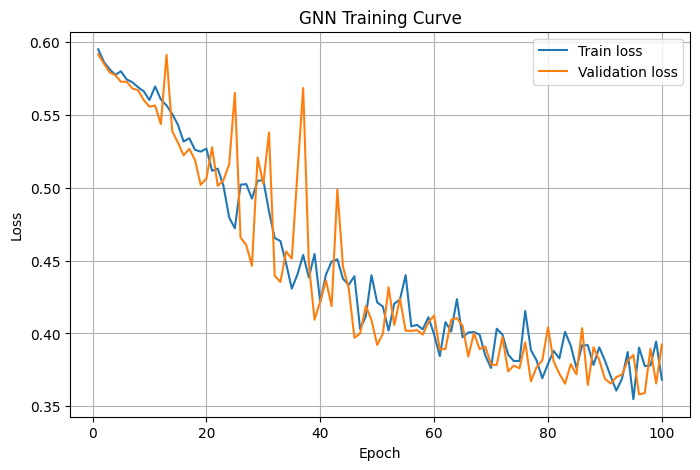

In [ ]:
#Vẽ training curve
history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GNN Training Curve")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Chọn threshold tốt trên validation
model.load_state_dict(torch.load(RESULT_DIR / "best_gnn_model.pt"))
model.eval()

val_loss, y_val_true, y_val_prob = run_epoch(
    model,
    val_loader,
    criterion
)

fpr, tpr, thresholds = roc_curve(y_val_true, y_val_prob)

best_index = np.argmax(tpr - fpr)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)

val_metrics = compute_metrics(
    y_val_true,
    y_val_prob,
    threshold=best_threshold
)

val_metrics

Best threshold: 0.48000798


{'ACC': 0.815068493150685,
 'Precision': 0.9242424242424242,
 'Sensitivity/Sn': 0.7349397590361446,
 'Specificity/Sp': np.float64(0.9206349206349206),
 'F1': 0.8187919463087249,
 'AUC': np.float64(0.8940524000764963),
 'Balanced Accuracy': np.float64(0.8277873398355327)}

In [ ]:
#Test evaluation
test_loss, y_test_true, y_test_prob = run_epoch(
    model,
    test_loader,
    criterion
)

test_metrics = compute_metrics(
    y_test_true,
    y_test_prob,
    threshold=best_threshold
)

print("GNN Test Metrics")
print("=" * 50)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.6f}")

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("\nClassification Report:")
print(classification_report(y_test_true, y_test_pred, digits=6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

GNN Test Metrics
ACC: 0.754098
Precision: 0.794118
Sensitivity/Sn: 0.771429
Specificity/Sp: 0.730769
F1: 0.782609
AUC: 0.861783
Balanced Accuracy: 0.751099

Classification Report:
              precision    recall  f1-score   support

         0.0   0.703704  0.730769  0.716981        78
         1.0   0.794118  0.771429  0.782609       105

    accuracy                       0.754098       183
   macro avg   0.748911  0.751099  0.749795       183
weighted avg   0.755581  0.754098  0.754636       183


Confusion Matrix:
[[57 21]
 [24 81]]


**Lưu kết quả GNN**

In [ ]:
pd.DataFrame(history).to_csv(
    RESULT_DIR / "gnn_training_history.csv",
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    RESULT_DIR / "gnn_test_metrics.csv",
    index=False
)

pd.DataFrame({
    "y_true": y_test_true,
    "y_prob": y_test_prob,
    "y_pred": y_test_pred
}).to_csv(
    RESULT_DIR / "gnn_test_predictions.csv",
    index=False
)

with open(RESULT_DIR / "gnn_best_threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("GNN results saved to:", RESULT_DIR)

GNN results saved to: /content/drive/MyDrive/gene_project/results_gnn
